# Fergus et al. (2006): Variational Bayesian PSF Estimation

Reproduction implementation by Codex.

This notebook uses a four-component zero-mean Gaussian mixture for image gradients, a four-component exponential mixture for the PSF, and a Gamma distribution for noise precision. It updates gradient and PSF means and variances, accepting updates after checking that the ELBO increases.

Set IMAGE_PATH to any Pillow-supported photograph, such as IMG_1586.JPG or fountain1_blurry.tif. EXIF orientation is applied before resizing. The image is resized proportionally to a longest edge of 771 pixels, matching the fountain image's working resolution, and a centered 300 x 300 ROI is selected automatically (reduced to fit when necessary). Small inputs are upsampled to the same working resolution, which does not recover missing detail. The preview and restored output use this working resolution.

The inference parameters are unchanged: horizontal-line initialization, final kernel size 37 x 37, exponential-mixture rate multiplier 2, convergence tolerance 1e-6 bits/pixel, and a limit of 150 iterations per scale. Gradient-pyramid downsampling uses bilinear interpolation with antialiasing. Scales that reach 150 iterations are recorded as having reached the iteration limit, rather than being reported as converged. The fixed kernel size represents blur in working-image pixels; resizing alone cannot guarantee that different photographs have the same blur extent.

The top row shows the posterior mean before thresholding. The middle row shows kernels postprocessed with the paper's max(K)/15 threshold. The bottom row shows Poisson reconstructions from the inferred gradients. Hoyer sparsity is computed from the top row; values closer to 1 indicate greater sparsity. Its monotonic increase across scales is an observed result, not an inference constraint.

The learned gradient priors come from linear_street_4.mat in the [authors' v1.2 release](https://cs.nyu.edu/~fergus/code/deblur_code_1_2.zip). The exponential-mixture rates are based on train_ensemble_evidence6.m. The multiplier of 2 is an additional tuning choice. See the [original paper](https://people.csail.mit.edu/billf/publications/Removing_Camera_Shake.pdf).

The implementation covers mean-field VB with fixed mixture weights. It does not include a line-by-line port of the public MATLAB implementation's mixture-weight learning, mean-offset estimation, staged noise updates, or custom line search. It does not exactly reproduce Figure 3.

PIL, NumPy, and SciPy are used for computation; Matplotlib is used for visualization.


Image: [771, 513] -> [771, 513]; ROI=(106, 406, 235, 535)


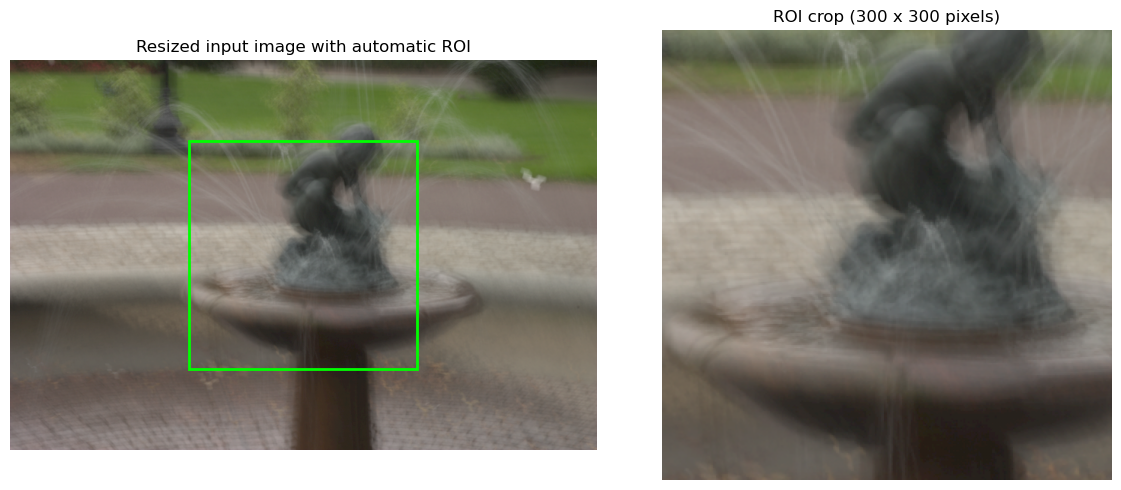

In [4]:
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps
from scipy import signal, ndimage, special
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt

IMAGE_PATH = Path('/Users/yfujimura/Downloads/deblur_images/fountain1_blurry.tif')
#IMAGE_PATH = Path('IMG_1586.JPG')
OUT = Path.cwd()
PRIORS = [{"pi":[0.3424340310728903,0.40767651333052146,0.07812420385914433,0.1717652517374289],"precision":[0.29802001130266303,3.0573335190267334,0.0014491231427730406,0.01704592730142977]},{"pi":[0.3190705041263619,0.09596426181604158,0.3879939885023601,0.19697124555521656],"precision":[0.6353124313785059,0.0028742740247449322,5.9569282007663,0.03574942831297822]},{"pi":[0.09976787553775796,0.3548257534999502,0.21415238959909377,0.33125398136318857],"precision":[0.004147895133134799,9.91287418753391,0.052356814834793375,1.0760367256192498]},{"pi":[0.0806457697881914,0.3531087529161156,0.33509045272367893,0.23115502457201323],"precision":[0.0050454695734232,16.54712911833657,1.5114534596710867,0.0603056841619064]},{"pi":[0.3837669289986711,0.2549862266831338,0.05017782885585161,0.31106901546234117],"precision":[2.1968983384539866,0.0629588203406576,0.004338338495067549,31.45072207040538]},{"pi":[0.2361579503716776,0.02410007746499708,0.3889560888676661,0.3507858832956606],"precision":[0.0494504494719423,0.002400522386224243,27.772678182031825,1.3818254410186852]},{"pi":[0.3750836558156682,0.2278563970606603,0.3907337897732923,0.006326157350377128],"precision":[30.87423860368161,0.03422103832974795,1.3676396026917672,0.0006615342462320538]},{"pi":[0.36546849898726225,0.4444363146286955,0.003820813210408265,0.18627437317363424],"precision":[0.665507621417974,21.146669814425323,0.00031931372931303,0.023160504210950776]}]
# precision=gamma in the author's .mat file: this is inverse variance.
KERNEL_RATE_SCALE = 2.0  # exponential-mixture rate multiplier, tuned for this ROI
KERNEL_RATE = KERNEL_RATE_SCALE * np.array([5114.3, 5006.4, 173.8885, 50.6538])
KERNEL_PI = np.array([787.8988, 201.7349, 236.1948, 143.1756])
KERNEL_PI /= KERNEL_PI.sum()
WORKING_LONG_EDGE = 771  # same working resolution as the fountain image
ROI_SIZE = 300  # automatically select a square near the image center
MAX_BLUR = 37
MAX_ITER = 150  # verified iteration budget; raise for a stricter convergence study
TOL_BITS = 1e-6
INITIAL_DIRECTION = 'horizontal'
NOISE_SHAPE = NOISE_RATE = 1e-3

def prepare_image(image_path, long_edge=WORKING_LONG_EDGE, roi_size=ROI_SIZE):
    """Apply EXIF orientation, resize proportionally, and select a centered ROI."""
    image_path = Path(image_path).expanduser()
    if not image_path.is_file():
        raise FileNotFoundError(f'Input image not found: {image_path.resolve()}')
    with Image.open(image_path) as source:
        image = ImageOps.exif_transpose(source).convert('RGB')
    original_size = image.size
    scale = long_edge / max(original_size)
    working_size = tuple(max(1, int(round(side * scale))) for side in original_size)
    if min(working_size) < 2 * MAX_BLUR + 1:
        raise ValueError('Image is too narrow for the fixed blur size. Increase WORKING_LONG_EDGE.')
    if working_size != original_size:
        image = image.resize(working_size, resample=Image.Resampling.LANCZOS)
    width, height = image.size
    side = min(roi_size, height, width)
    y0, x0 = (height - side) // 2, (width - side) // 2
    roi = (y0, y0 + side, x0, x0 + side)
    info = dict(input_path=str(image_path.resolve()), original_size=list(original_size),
                working_size=list(working_size), resize_scale=scale)
    return np.asarray(image, dtype=float) / 255, roi, info

# Preview the working-resolution image and automatically selected ROI.
rgb, ROI, image_info = prepare_image(IMAGE_PATH)
y0, y1, x0, x1 = ROI
print(f'Image: {image_info["original_size"]} -> {image_info["working_size"]}; ROI={ROI}')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb)
axes[0].add_patch(plt.Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0,
                                 fill=False, edgecolor='lime', linewidth=2))
axes[0].set_title('Resized input image with automatic ROI')
axes[1].imshow(rgb[y0:y1, x0:x1])
axes[1].set_title(f'ROI crop ({x1 - x0} x {y1 - y0} pixels)')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'fergus_vb_roi.png', dpi=160, bbox_inches='tight')
plt.show()

def resize(a, shape):
    """Pixel-centre bilinear interpolation with scaled tent antialias filter."""
    result = a
    for axis, n in enumerate(shape):
        old = result.shape[axis]
        scale = n / old
        coord = (np.arange(n) + .5) / scale - .5
        weights = np.maximum(0, 1 - np.abs(coord[:, None] - np.arange(old)[None, :])
                             * min(1, scale))
        weights /= weights.sum(axis=1, keepdims=True)
        # Sparse interpolation matrices avoid dense image-size matrix products.
        result = (csr_matrix(weights) @ result if axis == 0
                  else (csr_matrix(weights) @ result.T).T)
    return result

def hoyer(k):
    """0=dense uniform, 1=one nonzero; invariant to PSF amplitude."""
    a = np.asarray(k).ravel()
    return (np.sqrt(a.size) - a.sum() / np.linalg.norm(a)) / (np.sqrt(a.size) - 1)

def conv(a, b):
    return signal.fftconvolve(a, b, mode='same')

def corr(a, b):
    return signal.fftconvolve(a, b[::-1, ::-1], mode='same')

def positive_moments(eta, precision):
    # q(k) ∝ exp(eta*k - precision*k²/2), k >= 0.
    # erfcx + asymptotic branch follows train_ensemble_rectified5.m.
    t = -eta / np.sqrt(2 * precision)
    m = np.empty_like(eta); s = np.empty_like(eta); ent = np.empty_like(eta)
    regular = t <= 25
    a, b, z = eta[regular], precision[regular], t[regular]
    inv = 1 / special.erfcx(z)
    m[regular] = a/b + np.sqrt(2/np.pi/b)*inv
    s[regular] = (a/b)**2 + 1/b + 2*a/b/np.sqrt(2*np.pi*b)*inv
    logZ = .5*np.log(2*np.pi/b) + .5*a*a/b + special.log_ndtr(a/np.sqrt(b))
    ent[regular] = logZ - a*m[regular] + .5*b*s[regular]
    a, b = eta[~regular], precision[~regular]
    m[~regular] = -1/a + 2*b/a**3 - 10*b*b/a**5
    s[~regular] = 2/a**2 - 10*b/a**4 + 74*b*b/a**6
    ent[~regular] = -(np.log(-a)-1+2*b/a**2-7.5*b*b/a**4
                        +(148/3)*b**3/a**6)
    return m, np.maximum(s, m*m), ent

def moments(state):
    e, p, ke, kp = state
    g = e/p
    g2 = g*g + 1/p
    k, k2, hk = positive_moments(ke, kp)
    return g, g2, k, k2, hk

def responsibilities(g2, k, prior):
    pi = np.array(prior['pi'])
    tau = np.array(prior['precision'])
    lg = np.log(pi)[:,None,None,None] + .5*np.log(tau)[:,None,None,None] \
         - .5*np.log(2*np.pi) - .5*tau[:,None,None,None]*g2[None]
    lk = np.log(KERNEL_PI)[:,None,None] + np.log(KERNEL_RATE)[:,None,None] \
         - KERNEL_RATE[:,None,None]*k[None]
    rg = np.exp(lg-special.logsumexp(lg,axis=0))
    rk = np.exp(lk-special.logsumexp(lk,axis=0))
    return rg, rk, lg, lk

def statistics(state, y, mask, prior):
    g,g2,k,k2,hk = moments(state)
    prediction = np.array([conv(v,k) for v in g])
    # E[(Y-K*G)^2] includes BOTH posterior variances:
    # E[K²]*E[G²] - E[K]²*E[G]². No MAP substitution.
    uncertainty = np.array([conv(v,k2)-conv(m*m,k*k) for v,m in zip(g2,g)])
    sse = max(float(np.sum(mask*((y-prediction)**2+uncertainty))),1e-12)
    n = float(mask.sum())
    a = NOISE_SHAPE + n/2
    b = NOISE_RATE + sse/2
    beta = a/b
    rg,rk,lg,lk = responsibilities(g2,k,prior)
    # ELBO with q(z) and q(beta) analytically maximized.
    # Dropped terms are constant within this scale.
    entropy_g = .5*np.sum(np.log(2*np.pi*np.e/state[1]))
    bound = (-a*np.log(b) + entropy_g + hk.sum()
             + special.logsumexp(lg,axis=0).sum()
             + special.logsumexp(lk,axis=0).sum())
    return bound, beta, (g,g2,k,k2,prediction,rg,rk), sse

def proposal(state, y, mask, prior, update_kernel):
    bound,beta,stats,sse = statistics(state,y,mask,prior)
    g,g2,k,k2,pred,rg,rk = stats
    residual = mask*(y-pred)
    if update_kernel:
        # Adjoints of *nonperiodic* same convolution, restricted to kernel support.
        size = k.shape[0]; h,w = y.shape[-2:]
        # Full correlation zero lag lies at (h-1,w-1).
        def kernel_corr(a,b):
            full=signal.fftconvolve(a,b[::-1,::-1],mode='full')
            sy,sx=h-1-size//2,w-1-size//2
            return full[sy:sy+size,sx:sx+size]
        linear=np.zeros_like(k); quad=np.zeros_like(k)
        for j in range(2):
            linear += kernel_corr(residual[j],g[j]) + k*kernel_corr(mask[j],g[j]*g[j])
            quad += kernel_corr(mask[j],g2[j])
        rate=(rk*KERNEL_RATE[:,None,None]).sum(axis=0)
        ke=beta*linear-rate
        kp=np.maximum(beta*quad,1e-12)
        new=(state[0],state[1],ke,kp)
    else:
        tau=np.array(prior['precision'])
        prior_precision=(rg*tau[:,None,None,None]).sum(axis=0)
        linear=np.array([corr(r,k) for r in residual])
        diagonal=np.array([corr(m,k*k) for m in mask])
        quad=np.array([corr(m,k2) for m in mask])
        e=beta*(linear+g*diagonal)
        p=np.maximum(prior_precision+beta*quad,1e-12)
        new=(e,p,state[2],state[3])
    return new

def infer(y, mask, k0, g0, prior, max_iter=MAX_ITER, clamp_kernel=False):
    # Natural parameters, not projected least squares.
    p=np.full_like(y,1e4)
    kp=np.full_like(k0,1e6)
    state=(g0*p,p,k0*kp,kp)
    history=[]
    for iteration in range(max_iter):
        previous=statistics(state,y,mask,prior)[0]
        for update_kernel in ([False] if clamp_kernel else [False,True]):
            target=proposal(state,y,mask,prior,update_kernel)
            old_bound=statistics(state,y,mask,prior)[0]
            # Damped natural-parameter updates accepted ONLY if ELBO increases.
            alpha=1.
            for trial in range(24):
                candidate=tuple(a+alpha*(b-a) for a,b in zip(state,target))
                new_bound=statistics(candidate,y,mask,prior)[0]
                if np.isfinite(new_bound) and new_bound>=old_bound-1e-7:
                    state=candidate
                    break
                alpha*=.5
        bound,beta,_,sse=statistics(state,y,mask,prior)
        history.append((bound,beta,sse))
        improvement=(bound-previous)/mask.sum()/np.log(2)
        if iteration>=15 and improvement<TOL_BITS:
            break
    return state,np.array(history)

def poisson(g, reference):
    # Reference-only intensity recovery from inferred (not integrability-constrained) gradients.
    h,w=reference.shape
    dx=np.exp(2j*np.pi*np.fft.fftfreq(w)[None,:])-1
    dy=np.exp(2j*np.pi*np.fft.fftfreq(h)[:,None])-1
    d=np.abs(dx)**2+np.abs(dy)**2; d[0,0]=1
    out=np.fft.ifft2((np.conj(dx)*np.fft.fft2(g[0])
                     +np.conj(dy)*np.fft.fft2(g[1]))/d).real
    return out-out.mean()+reference.mean()


scale 1: (26, 26), K=3, steps=150, Hoyer=0.4636, noise precision=17.612, mass=0.9458
scale 2: (37, 37), K=5, steps=150, Hoyer=0.5319, noise precision=8.8622, mass=1.1534
scale 3: (53, 53), K=7, steps=150, Hoyer=0.5588, noise precision=6.8918, mass=1.8600
scale 4: (75, 75), K=9, steps=150, Hoyer=0.5696, noise precision=6.434, mass=2.7381
scale 5: (106, 106), K=13, steps=150, Hoyer=0.6202, noise precision=3.7711, mass=3.4288
scale 6: (150, 150), K=19, steps=150, Hoyer=0.6987, noise precision=2.362, mass=3.6491
scale 7: (211, 211), K=27, steps=150, Hoyer=0.6944, noise precision=1.6267, mass=3.9111
scale 8: (299, 299), K=37, steps=150, Hoyer=0.7346, noise precision=0.72222, mass=5.3114


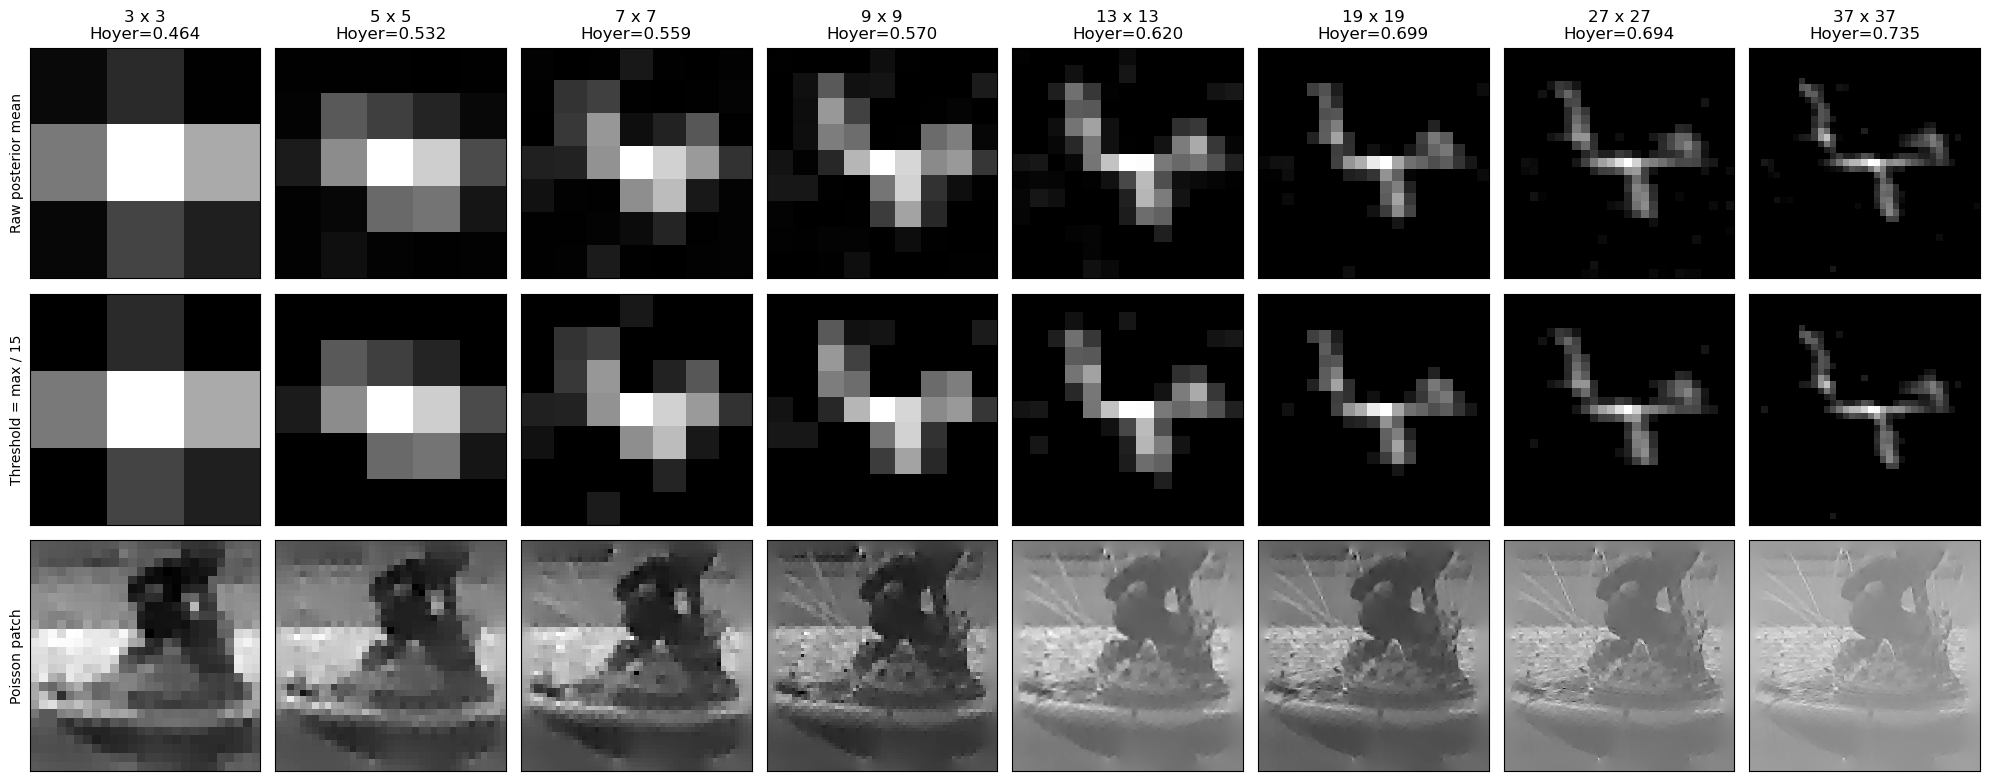

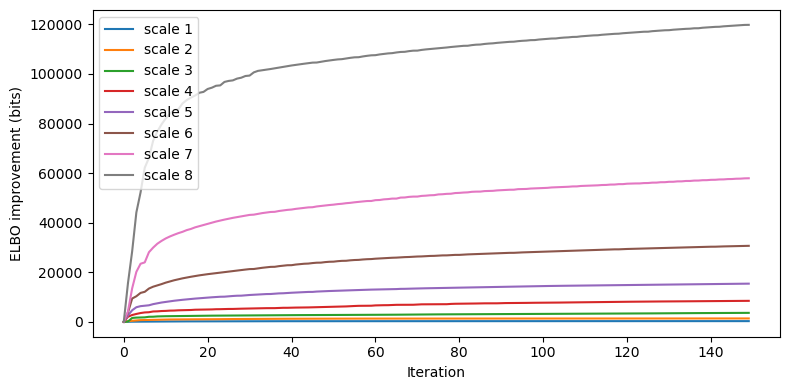

{
  "image": {
    "input_path": "/Users/yfujimura/Downloads/deblur_images/fountain1_blurry.tif",
    "original_size": [
      771,
      513
    ],
    "working_size": [
      771,
      513
    ],
    "resize_scale": 1.0
  },
  "roi": [
    106,
    406,
    235,
    535
  ],
  "max_blur": 37,
  "rate_multiplier": 2.0,
  "tolerance_bits_per_pixel": 1e-06,
  "max_iterations": 150,
  "scales": [
    {
      "size": 3,
      "hoyer_raw": 0.4635825767430024,
      "iterations": 150,
      "iteration_limit_reached": true
    },
    {
      "size": 5,
      "hoyer_raw": 0.5319453968900216,
      "iterations": 150,
      "iteration_limit_reached": true
    },
    {
      "size": 7,
      "hoyer_raw": 0.5587665387110272,
      "iterations": 150,
      "iteration_limit_reached": true
    },
    {
      "size": 9,
      "hoyer_raw": 0.5696314283497653,
      "iterations": 150,
      "iteration_limit_reached": true
    },
    {
      "size": 13,
      "hoyer_raw": 0.6202162618412576,
      "ite

1463

In [5]:
# Published priors were learned in ~0..255 linear intensity units.
gray=(.299*rgb[...,0]+.587*rgb[...,1]+.114*rgb[...,2])
linear=gray**2.2*255
y0,y1,x0,x1=ROI
patch=linear[y0:y1,x0:x1]
gradients=np.array([np.diff(patch,axis=1)[:-1],np.diff(patch,axis=0)[:,:-1]])
scale_factors=2.**(-np.arange(7,-1,-1)/2)
# Odd supports give an unambiguous adjoint for scipy's same convolution.
sizes=[3,5,7,9,13,19,27,MAX_BLUR]
kernel=np.zeros((3,3))
if INITIAL_DIRECTION=='horizontal': kernel[1,:]=1/3
else: kernel[:,1]=1/3
history=[]; g=None
for level,(factor,size) in enumerate(zip(scale_factors,sizes)):
    shape=tuple(max(size+4,int(round(v*factor))) for v in gradients.shape[1:])
    y=np.array([resize(v,shape) for v in gradients])
    mask=np.ones_like(y)
    r=size//2
    mask[:,:r]=0; mask[:,-r:]=0; mask[:,:,:r]=0; mask[:,:,-r:]=0
    kernel=resize(kernel,(size,size)); kernel/=kernel.sum()
    g=y.copy() if g is None else np.array([resize(v,shape) for v in g])
    prior=PRIORS[7-level]
    if level==0:
        fixed,_=infer(y,mask,kernel,g,prior,max_iter=100,clamp_kernel=True)
        g=moments(fixed)[0]
    state,trace=infer(y,mask,kernel,g,prior)
    g,g2,kernel,k2,_=moments(state)
    reference=resize(patch,shape)
    latent=poisson(g,reference)
    history.append(dict(kernel=kernel.copy(),latent=latent,trace=trace,
                        variance=k2-kernel**2,gradient_variance=g2-g*g))
    print(f'scale {level+1}: {shape}, K={size}, steps={len(trace)}, Hoyer={hoyer(kernel):.4f}, '
          f'noise precision={trace[-1,1]:.5g}, mass={kernel.sum():.4f}',flush=True)

# Raw mean is retained separately from the final thresholded, normalized PSF.
raw_kernel=kernel.copy()
kernel=raw_kernel/raw_kernel.sum()
clean_kernel=kernel.copy()
clean_kernel[clean_kernel<clean_kernel.max()/15]=0
clean_kernel/=clean_kernel.sum()
np.savez(OUT/'fergus_vb_kernel.npz',kernel=kernel,raw_mean=raw_kernel,
         cleaned_kernel=clean_kernel,variance=(k2-raw_kernel**2)/raw_kernel.sum()**2)
fig,axes=plt.subplots(3,8,figsize=(20,8))
for i,item in enumerate(history):
    k=item['kernel']
    display=k.copy(); display[display<display.max()/15]=0
    axes[0,i].imshow(k,cmap='gray',vmin=0,vmax=k.max(),interpolation='nearest')
    axes[0,i].set_title(f"{sizes[i]} x {sizes[i]}\nHoyer={hoyer(k):.3f}")
    axes[1,i].imshow(display,cmap='gray',vmin=0,vmax=k.max(),interpolation='nearest')
    axes[2,i].imshow(np.clip(item['latent']/255,0,1)**(1/2.2),cmap='gray')
    for ax in axes[:,i]: ax.set_xticks([]);ax.set_yticks([])
axes[0,0].set_ylabel('Raw posterior mean')
axes[1,0].set_ylabel('Threshold = max / 15')
axes[2,0].set_ylabel('Poisson patch')
fig.tight_layout()
fig.savefig(OUT/'fergus_vb_multiscale.png',dpi=160)
plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for i,item in enumerate(history):
    trace=item['trace'][:,0]
    assert np.all(np.diff(trace)>=-1e-5), 'ELBO decreased'
    ax.plot((trace-trace[0])/np.log(2),label=f'scale {i+1}')
ax.set(xlabel='Iteration',ylabel='ELBO improvement (bits)')
ax.legend();fig.tight_layout()
fig.savefig(OUT/'fergus_vb_elbo.png',dpi=140)
plt.show()
import json
report = {
    'image':image_info,
    'roi':list(ROI), 'max_blur':MAX_BLUR, 'rate_multiplier':KERNEL_RATE_SCALE,
    'tolerance_bits_per_pixel':TOL_BITS,'max_iterations':MAX_ITER,
    'scales':[
        dict(size=sizes[i],hoyer_raw=float(hoyer(v['kernel'])),
             iterations=len(v['trace']),iteration_limit_reached=len(v['trace'])==MAX_ITER)
        for i,v in enumerate(history)]
}
print(json.dumps(report,indent=2))
# This report explicitly records iteration limits rather than claiming convergence.
(OUT/'fergus_vb_tuning.json').write_text(json.dumps(report,indent=2))


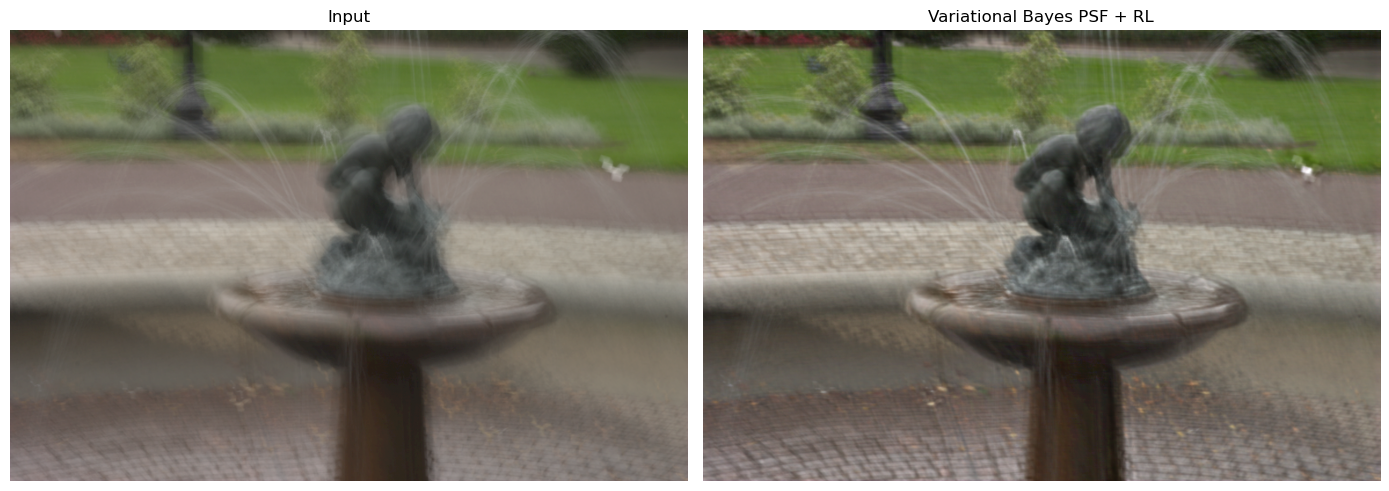

In [6]:
def restore_rl(image,k,iterations=10):
    k=k.copy()
    k[k<k.max()/15]=0
    k/=k.sum()
    pad=max(k.shape)
    result=np.empty_like(image)
    for c in range(3):
        observed=np.pad(image[...,c],pad,mode='reflect')
        estimate=np.maximum(observed,1e-6)
        for _ in range(iterations):
            ratio=observed/np.maximum(conv(estimate,k),1e-6)
            estimate*=corr(ratio,k)
        result[...,c]=estimate[pad:-pad,pad:-pad]
    return np.clip(result,0,1)
restored=restore_rl(rgb**2.2,kernel,10)**(1/2.2)
Image.fromarray(np.uint8(np.rint(restored*255))).save(OUT/'fergus_vb_restored.png')
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].imshow(rgb);ax[0].set_title('Input')
ax[1].imshow(restored);ax[1].set_title('Variational Bayes PSF + RL')
for a in ax:a.axis('off')
fig.tight_layout();plt.show()
